![Banner](./img/AI_Special_Program_Banner.jpg)

## CNN Exercise
---
Instructions are given in <span style="color:teal">blue</span> color.

For this exercise, you are asked to implement a convolutional neural network based on a proposed architecture to classify objects in the [world's largest doodling dataset](https://quickdraw.withgoogle.com/data).

```Quick, Draw!``` is a project by Google in which people are asked to draw images of certain objects in a limited amount of time. You can actually contribute to the project yourself by visiting [this page](https://quickdraw.withgoogle.com/) and start doodling away. Can you muster the artistic skills it takes to get your images recognized?

The entire dataset contains more than 50 million drawings across more than 300 different categories. Luckily, the whole dataset [has been made open-source](https://github.com/googlecreativelab/quickdraw-dataset), allowing us to use the data for our own neural network training.

Since trying to classify the entire dataset in a single exercise would be a little overwhelming, we will be focusing on a subset of the drawings instead. However, we still want to tackle a little challenge. This is why we will be working with doodles that are not always as easily distinguishable - not even for the human eye.

In [1]:
# The categories we want to classify
classes = ['Apple', 'Baseball', 'Basketball', 'Blueberry', 'Circle', 'Clock', 'Cookie', 'Donut', 'Face', 'Pizza']

In [2]:
# Packages and libraries
import numpy as np
import matplotlib.pyplot as plt

from torch import nn
from torch.utils.data import Dataset, DataLoader
import torch.optim as optim
from tqdm.notebook import trange, tqdm
import torch

import warnings
warnings.filterwarnings("ignore")

<span style="color:teal">As in the material notebook, please perform the usual preparations like importing the helper functions for the training loop, ensuring reproducibility, and choosing the appropriate device</span>

In [3]:
# imports
import datetime as dt
from pt_utils import set_seed, print_execution_details, get_default_device, report_device
from pt_utils import train, train_for_epochs, validate, predict_batch, plot_history

In [4]:
%matplotlib inline

In [5]:
# Random seed
RSEED = 42
set_seed(RSEED)

In [6]:
# execution details
print_execution_details(show_libraries=False)

Python   : 3.12.2
PyTorch  : 2.13.0+cpu
Platform : Windows 11
CUDA available: False


In [7]:
# --- DEVICE CONFIGURATION ---
USE_CPU = False
device = get_default_device(USE_CPU)
report_device(USE_CPU, device)

Using CPU (no CUDA device available)


In [8]:
# Data source path
source_path = "data/Quick_Draw/"

# Images and labels
training_img_file = "QD_Training_Data.npy"
validation_img_file = "QD_Validation_Data.npy"
testing_img_file = "QD_Testing_Data.npy"
training_label_file = "QD_Training_Labels.npy"
validation_label_file = "QD_Validation_Labels.npy"
testing_label_file = "QD_Testing_Labels.npy"

## 1. Import the data

* <div style="color:teal">Your first task will be to get the data ready to work with on your local machine. You can download the data from this course's Moodle page. In total, four files have been prepared for you: the training data, the validation data, and the testing data along with their respective labels. All files are stored in the binary <code>.npy</code> format. Load the content of these files into your workspace with the help of NumPy's <code>load()</code> function.</div>

In [9]:
# Your solution goes here:
training_img = np.load(source_path + training_img_file)
validation_img = np.load(source_path + validation_img_file)
testing_img = np.load(source_path + testing_img_file)

training_label = np.load(source_path + training_label_file)
validation_label = np.load(source_path + validation_label_file)
testing_label = np.load(source_path + testing_label_file)

print("Loaded arrays (images / labels):")
for name, arr in [('training', training_img), ('validation', validation_img), ('testing', testing_img)]:
    print(f"  {name:11s}: images {arr.shape}  dtype={arr.dtype}")

Loaded arrays (images / labels):
  training   : images (350000, 28, 28, 1)  dtype=uint8
  validation : images (100000, 28, 28, 1)  dtype=uint8
  testing    : images (50000, 28, 28, 1)  dtype=uint8


## 2. Explore the data

* <div style="color:teal">Find out how many samples there are for training, validation and testing.</div>

In [10]:
# Your solution goes here:
print(f"Training samples  : {len(training_img):,}")
print(f"Validation samples: {len(validation_img):,}")
print(f"Testing samples   : {len(testing_img):,}")

Training samples  : 350,000
Validation samples: 100,000
Testing samples   : 50,000


* <div style="color:teal">Are the classes balanced? Find out how many samples there are for each category in the three datasets and chose an appropriate way to visualize this.</div>

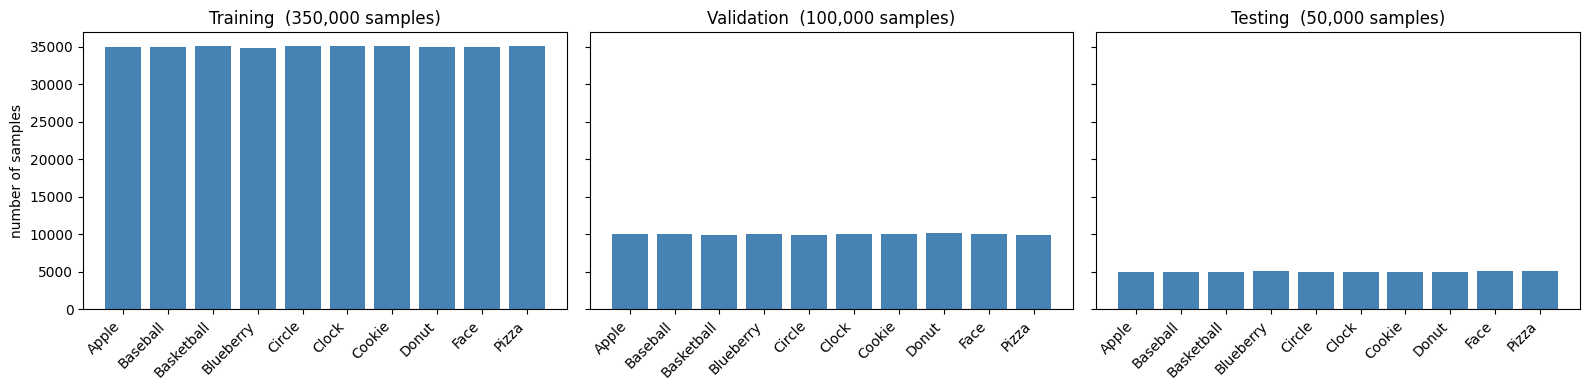

Training   : 34891-35161 samples per class (spread 0.8% of the mean) -> very well balanced
Validation : 9893-10158 samples per class (spread 2.6% of the mean) -> very well balanced
Testing    : 4932-5107 samples per class (spread 3.5% of the mean) -> very well balanced


In [11]:
# Your solution goes here:
# Count samples per class in each split and compare them side by side.
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, (name, labels) in zip(axes, [('Training', training_label),
                                      ('Validation', validation_label),
                                      ('Testing', testing_label)]):
    counts = np.bincount(labels.astype(int), minlength=len(classes))
    ax.bar(range(len(classes)), counts, color='steelblue')
    ax.set_xticks(range(len(classes)))
    ax.set_xticklabels(classes, rotation=45, ha='right')
    ax.set_title(f'{name}  ({len(labels):,} samples)')
axes[0].set_ylabel('number of samples')
plt.tight_layout(); plt.show()

for name, labels in [('Training', training_label), ('Validation', validation_label), ('Testing', testing_label)]:
    counts = np.bincount(labels.astype(int), minlength=len(classes))
    spread = (counts.max() - counts.min()) / counts.mean() * 100
    verdict = 'very well balanced' if spread < 5 else 'imbalanced'
    print(f"{name:11s}: {counts.min()}-{counts.max()} samples per class "
          f"(spread {spread:.1f}% of the mean) -> {verdict}")

Optimally, the results of your work should help to conclude that there is plenty of data to train with, and the classes are all very well-balanced. However, this is usually (and unfortunately) seldom the case. Try to think of a situation where there are not enough images to train a network.

One possible method to tackle this issue is found in **Data Augmentation**.

* <div style="color:teal">Please describe, in your own words, what Data Augmentation is and how it can be used to increase model performance.</div>

*Your solution (statement) goes here:*

**Data Augmentation** artificially enlarges a training set by applying small, label-preserving
transformations to the samples we already have. For images the typical operations are rotation,
shifting, zooming/cropping, flipping, or changing brightness/contrast and adding a little noise.
Each transformed copy still shows the *same* object, so its class label stays valid, only the
pixels change.

It improves model performance in two ways:

* **It creates more effective training data.** When only a few images per class are available,
  augmentation cheaply produces many extra variations to learn from, which is much easier than
  collecting and labelling new real images.
* **It reduces overfitting and improves generalization.** By seeing the same object shifted,
  rotated or scaled, the network is forced to learn the *invariant* shape of a class instead of
  memorizing exact pixel positions, so it performs better on unseen, slightly different inputs.

* <div style="color:teal">Visualize the <b>first</b> image of the training set in conjunction with its correct label (category).</div>

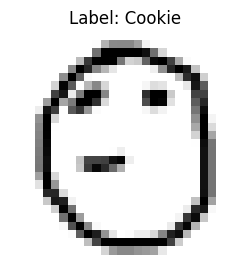

In [12]:
# Your solution goes here:
plt.figure(figsize=(3, 3))
plt.imshow(training_img[0].reshape(28, 28), cmap='gray_r')
plt.title(f'Label: {classes[int(training_label[0])]}')
plt.axis('off'); plt.show()

* <div style="color:teal">Visualize the <b>first 25 images</b> of the training set in conjunction with their correct labels (categories). Are you able to accurately identify each doodle?</div>

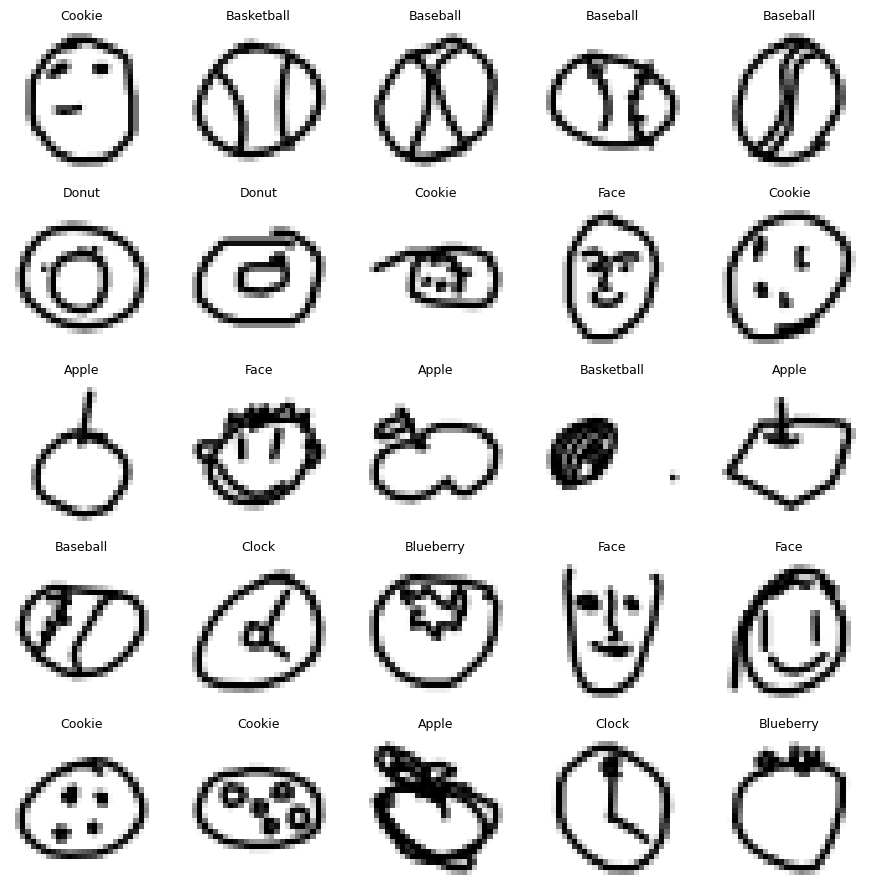

Not really - several doodles are ambiguous even for a human: at 28x28 an Apple, Cookie,
Donut, Clock and Circle all collapse to a rough circle, so some classes are genuinely hard
to tell apart. This is exactly the 'little challenge' mentioned in the intro.


In [13]:
# Your solution goes here:
fig, ax = plt.subplots(5, 5, figsize=(9, 9))
ax = ax.flatten()
for i in range(25):
    ax[i].imshow(training_img[i].reshape(28, 28), cmap='gray_r')
    ax[i].set_title(classes[int(training_label[i])], fontsize=9)
    ax[i].axis('off')
plt.tight_layout(); plt.show()

print("Not really - several doodles are ambiguous even for a human: at 28x28 an Apple, Cookie,\n"
      "Donut, Clock and Circle all collapse to a rough circle, so some classes are genuinely hard\n"
      "to tell apart. This is exactly the 'little challenge' mentioned in the intro.")

## 3. Preprocess the data and build a dataset

In terms of preprocessing the data, there is not much left for you to do. The provided image data has a similar format as the MNIST data you have seen several times by now.

* Images are represented by $28x28$ grayscale pixels.
* Each pixel holds a value between $0$ and $255$.

Before designing and training your network, you have to build a dataset and make sure those pixel values are scaled between 0 and 1. To do so, we have to

* build a PyTorch dataset and instantiate it for the training, validation, and test data;

* scale our data's pixel values to the range <b>[0, 1]</b>.

When doing so, we must make sure to perform all preprocessing tasks on our training as well as our validation and test data.

In [14]:
# build a dataset
class DoodleDataset(Dataset):

    def __init__(self, data, labels):
        self.labels = torch.from_numpy(labels)
        # scale pixel values to [0, 1] AND turn the array into a tensor in one step
        self.data = torch.from_numpy(data).float() / 255

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        label = self.labels[idx].long()
        img = self.data[idx].float().view(1, 28, 28)
        return img, label

train_dataset = DoodleDataset(training_img, training_label)
val_dataset = DoodleDataset(validation_img, validation_label)
test_dataset = DoodleDataset(testing_img, testing_label)

## 4. Build the model

Now that all the data is available and adequately preprocessed, it is time to create your convolutional neural network. Typically, the process of designing the model can take quite a while as there is no single best CNN architecture, taking into account the vast amount of hyperparameters and model options. Thus, finding a network structure that perfectly suits your data (and use-case) is a considerable effort on its own.

* <div style="color:teal">For this exercise, however, you will not design your own network. Instead, you are asked to implement the following CNN (using <code>PyTorch</code>):</div>

<img src="./img/Ex_CNN_Model_Visualization.png" width="1000"/>

* <div style="color:teal">Each convolutional layer applies a 3x3 filter with a 1x1 stride. The images will be padded so that the convolved feature maps retain the <b>same</b> size. The number of filters (kernels) should be taken from the visualization above.</div>
* <div style="color:teal">Subsampling is achieved by using Max-Pooling with a pool size of 2x2 (for each pooling layer).</div>
* <div style="color:teal">Apart from the final dense layer, activation happens with the help of the Rectified Linear Unit (ReLU). The last layer should output a probability distribution of the categories.</div>
* <div style="color:teal">After the first dense layer, dropout regularization is performed with a dropout rate of 0.5.</div>

**Hint**: Printing an instance of your model object will print an overview of your current model architecture. The CNN you are asked to implement should produce the following output:

<img src="./img/Ex_CNN_Model_Summary_PYTORCH.png" width="700"/>

In [15]:
# Your solution goes here:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        # every conv uses a 3x3 kernel, stride 1 and padding 1 -> feature maps keep their size ("same")
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, stride=1, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv3 = nn.Conv2d(32, 32, kernel_size=3, stride=1, padding=1)
        self.relu3 = nn.ReLU()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(32 * 7 * 7, 256)   # 32 x 7 x 7 = 1568 features after the two 2x2 poolings
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))     # 1x28x28 -> 16x14x14
        x = self.pool2(self.relu2(self.conv2(x)))     # -> 32x7x7
        x = self.relu3(self.conv3(x))                 # -> 32x7x7
        x = self.flatten(x)                           # -> 1568
        x = torch.relu(self.fc1(x))                   # ReLU on the first dense layer
        x = self.dropout(x)                           # dropout (p=0.5) after the first dense layer
        x = self.fc2(x)                               # final layer -> raw class logits (softmax is in CrossEntropyLoss)
        return x

model = CNN()
print(model)

CNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu3): ReLU()
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=1568, out_features=256, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)


## 5. Setup dataloader and optimizer

* <div style="color:teal">After defining the model architecture, you can now create a dataloader for the train, validation, and test dataset, setup an optimizer, and define a loss function. Use the Following:</div>

    * **Optimizer**: Adam
    * **Loss-Function**: torch.nn.CrossEntropyLoss
    * **Metrics**: Accuracy
   
Try to find a suitable value for the batch size (the number of images fed into the network at once). <br>
Also move the model to the correct device by calling <code>model.to(device)</code> on it

In [16]:
# Your solution goes here:
BATCH_SIZE = 256

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

model = model.to(device)                       # move the model to the chosen device
optimizer = optim.Adam(model.parameters())     # Adam optimizer
criterion = nn.CrossEntropyLoss()              # loss for multi-class classification

print(f"batch size: {BATCH_SIZE}")
print(f"batches -> train: {len(train_loader)}, val: {len(val_loader)}, test: {len(test_loader)}")

batch size: 256
batches -> train: 1368, val: 391, test: 196


The following sets up the train validation loop for training the network. <span style="color:teal">As in the material notebook, please use the helper functions for the training loop (see the imports above)</span>

## 6. Train the model

* <div style="color:teal">Now, train (fit) your model on the training data. Find suitable values for the number of epochs. (It is actually possible to reach close to 90% accuracy.)</div>

In [17]:
# Your solution goes here:
NUM_EPOCHS = 12

start = dt.datetime.now()
history = train_for_epochs(device, NUM_EPOCHS, model, train_loader, val_loader,
                           optimizer, criterion, binary=False)
print(f"\nTotal training time: {dt.datetime.now() - start}")

test_loss, test_acc = validate(device, model, test_loader, criterion)
print(f"Final test accuracy: {test_acc:.2f}%")

Epoch  1/12 | train loss 0.8004 acc 73.42% | val loss 0.5271 acc 82.93%


Epoch  2/12 | train loss 0.5231 acc 83.14% | val loss 0.4297 acc 85.93%


Epoch  3/12 | train loss 0.4668 acc 85.04% | val loss 0.4036 acc 86.76%


Epoch  4/12 | train loss 0.4337 acc 86.07% | val loss 0.3899 acc 87.23%


Epoch  5/12 | train loss 0.4105 acc 86.83% | val loss 0.3687 acc 87.97%


Epoch  6/12 | train loss 0.3909 acc 87.34% | val loss 0.3586 acc 88.24%


... (3 outputs left out)

Epoch 10/12 | train loss 0.3432 acc 88.81% | val loss 0.3344 acc 89.21%


Epoch 11/12 | train loss 0.3344 acc 89.06% | val loss 0.3440 acc 88.79%


Epoch 12/12 | train loss 0.3266 acc 89.35% | val loss 0.3300 acc 89.42%

Total training time: 0:35:41.334991


Final test accuracy: 89.22%


* <div style="color:teal">Visualize how the accuracy and the loss values for both training and validation data have evolved during model training. Using this visualization, can you pinpoint a moment where your model starts overfitting? How would you avoid this behavior?</div>

**Hint:** You can go ahead and start with a moderate number of epochs (say 10) and continue training afterwards as we did in the material notebook.

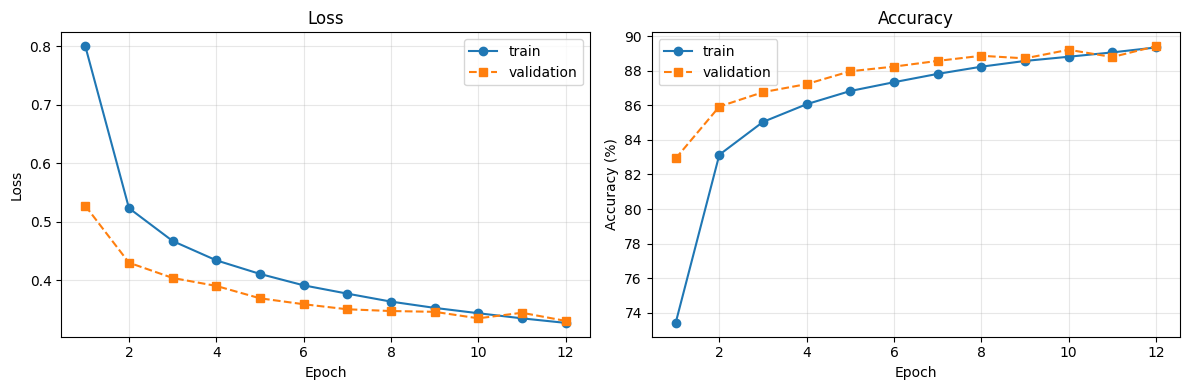

In [18]:
# Your solution goes here:
plot_history(history)
plt.show()

*Your solution (statement) goes here:*

Reading the curves:

* **Training keeps improving monotonically:** training accuracy rises from ~73% to ~89% and the training loss falls steadily (~0.80 -> ~0.33) across all 12 epochs.
* **Validation improves fast, then plateaus:** validation accuracy climbs to ~88-89% by around **epoch 8** and then essentially flattens, only wobbling between ~88.8% and ~89.4%; the validation loss likewise flattens and turns noisy (it bumps up at epoch 11 before dipping again at epoch 12).
* **Onset of overfitting:** in the early epochs the validation accuracy is actually *higher* than the training accuracy, which is normal because Dropout is active during training but switched off during evaluation. Around **epoch 10-11** the training accuracy catches up and overtakes the validation accuracy while the validation metrics stop improving. That crossover / plateau is the point where further training mostly benefits the training set only - i.e. the beginning of overfitting. Within 12 epochs it stays *mild* (the validation loss has flattened but not yet risen consistently), because Dropout(0.5) together with the very large 350k-image training set already regularize the model well.

**How to avoid it:** use **early stopping** (keep the weights from around the validation plateau, ~epoch 10), add more **regularization** (a higher dropout rate or `weight_decay` in Adam), apply **data augmentation**, or reduce the model's capacity. With ~89% test accuracy we already reached the "close to 90%" target.

## 7. Use the trained model

Around 90% test accuracy is a great result, given the inherently difficult task to identify very similar objects. Let us finally put the model to use and make some predictions.

* <div style="color:teal">Take the drawings at <b>index position 883</b> and <b>22866</b> in the testing set and predict thier respective categories using your model. Does your CNN classify the images correctly? What would you have guessed is depicted in those doodles?</div>

In [19]:
# function for predicting the class at a given index by a trained model
def predict(model, data):
    model.eval()
    data = data.unsqueeze(0).to(device)
    with torch.no_grad():
        #predict
        outputs = model(data).squeeze().cpu()
        # Get the prediction by selecting the class with the highest probability
        outputs = torch.softmax(outputs, 0)
        _, predicted = torch.max(outputs, 0)
        return predicted, outputs

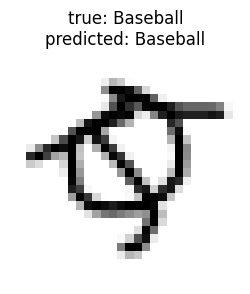

Index 883: true = Baseball, predicted = Baseball (confidence 64.4%)


In [20]:
# Your solution goes here for 883:
idx883 = 883
img883, true883 = test_dataset[idx883]
pred883, probs883 = predict(model, img883)
pred883, true883 = int(pred883), int(true883)

plt.figure(figsize=(3, 3))
plt.imshow(img883.squeeze().numpy(), cmap='gray_r')
plt.title(f'true: {classes[true883]}\npredicted: {classes[pred883]}')
plt.axis('off'); plt.show()

print(f"Index {idx883}: true = {classes[true883]}, predicted = {classes[pred883]} "
      f"(confidence {probs883[pred883]*100:.1f}%)")

* <div style="color:teal">Visualize the entire probability distribution for the prediction of that same image sample. What is your network's second-best guess?</div>

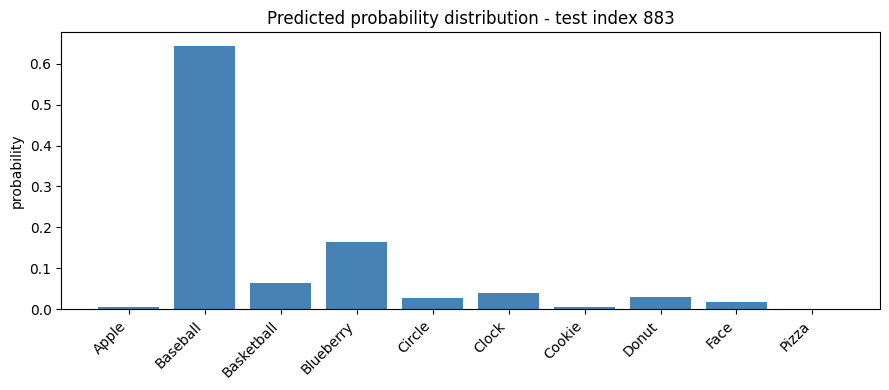

best guess : Baseball (64.4%)
2nd guess  : Blueberry (16.5%)


In [21]:
# Your solution goes here:
plt.figure(figsize=(9, 4))
plt.bar(classes, probs883.numpy(), color='steelblue')
plt.xticks(rotation=45, ha='right')
plt.ylabel('probability'); plt.title('Predicted probability distribution - test index 883')
plt.tight_layout(); plt.show()

top2 = torch.topk(probs883, 2)
print(f"best guess : {classes[int(top2.indices[0])]} ({top2.values[0]*100:.1f}%)")
print(f"2nd guess  : {classes[int(top2.indices[1])]} ({top2.values[1]*100:.1f}%)")

*Your solution (statement) goes here:*

Yes - the network classifies test image **883 correctly as *Baseball*** (confidence **64.4%**), and its **second-best guess is *Blueberry* (16.5%)**. That runner-up makes sense: at 28x28 a baseball is essentially a circle with a couple of curved stitching lines, and a blueberry is also a small round blob, so the two share almost the same round silhouette. The prediction is reasonably confident, and I would have guessed a baseball (or simply "a circle") myself.

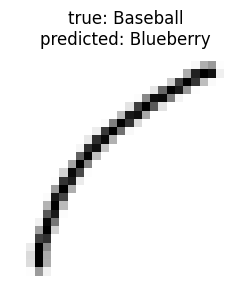

Index 22866: true = Baseball, predicted = Blueberry (confidence 15.9%)


In [22]:
# Your solution goes here for 22866:
idx22866 = 22866
img22866, true22866 = test_dataset[idx22866]
pred22866, probs22866 = predict(model, img22866)
pred22866, true22866 = int(pred22866), int(true22866)

plt.figure(figsize=(3, 3))
plt.imshow(img22866.squeeze().numpy(), cmap='gray_r')
plt.title(f'true: {classes[true22866]}\npredicted: {classes[pred22866]}')
plt.axis('off'); plt.show()

print(f"Index {idx22866}: true = {classes[true22866]}, predicted = {classes[pred22866]} "
      f"(confidence {probs22866[pred22866]*100:.1f}%)")

* <div style="color:teal">Visualize the entire probability distribution for the prediction of that same image sample. What are your thoughts?</div>

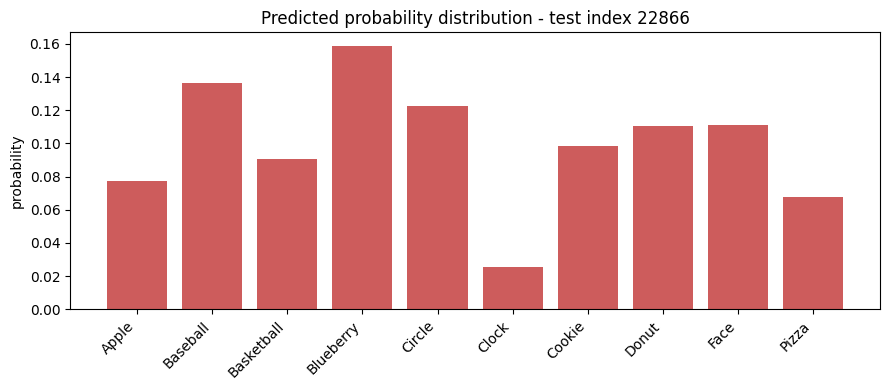

best guess : Blueberry (15.9%)
2nd guess  : Baseball (13.7%)


In [23]:
# Your solution goes here:
plt.figure(figsize=(9, 4))
plt.bar(classes, probs22866.numpy(), color='indianred')
plt.xticks(rotation=45, ha='right')
plt.ylabel('probability'); plt.title('Predicted probability distribution - test index 22866')
plt.tight_layout(); plt.show()

top2 = torch.topk(probs22866, 2)
print(f"best guess : {classes[int(top2.indices[0])]} ({top2.values[0]*100:.1f}%)")
print(f"2nd guess  : {classes[int(top2.indices[1])]} ({top2.values[1]*100:.1f}%)")

*Your solution (statement) goes here:*

Here the network is **wrong**: image **22866 is really a *Baseball*, but the model predicts *Blueberry***. What stands out is *how unsure* it is - the winning class gets only **15.9%**, with *Baseball* right behind at **13.7%**, and the whole probability distribution is nearly flat across the round-object classes (Baseball, Blueberry, Circle, Cookie, ...). So this is essentially a coin-flip, not a confident mistake. The doodle is genuinely ambiguous - a rough circle that could plausibly be several of the round categories - which is exactly the "not always easily distinguishable, not even for the human eye" challenge mentioned in the introduction. A human could easily make the same error.